## Model building and Pipelines

Here we will build actual pipeline and model .

In [320]:
from pathlib import Path
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

path=Path.cwd()
file_path=path.parent/'Data'/'cleaned_data.csv'
data=pd.read_csv(file_path)
df=data.copy()
df

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...,...
9995,M24855,M,298.8,308.4,1604,29.5,14,0
9996,H39410,H,298.9,308.4,1632,31.8,17,0
9997,M24857,M,299.0,308.6,1645,33.4,22,0
9998,H39412,H,299.0,308.7,1408,48.5,25,0


In [321]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, accuracy_score,confusion_matrix
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer


In [322]:
df['MachineFailure'].value_counts()

MachineFailure
0    9661
1     339
Name: count, dtype: int64

In [323]:
df.head()

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0


In [324]:
df.shape

(10000, 8)

In [325]:
X=df.drop(columns=['MachineFailure', 'Product ID'],axis=1)
y=df['MachineFailure']

In [326]:
X

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9
...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14
9996,H,298.9,308.4,1632,31.8,17
9997,M,299.0,308.6,1645,33.4,22
9998,H,299.0,308.7,1408,48.5,25


In [327]:
X_train,X_test,y_train,y_test=train_test_split(X,y , test_size=0.2, random_state=42,stratify=y)

In [328]:
X_train.shape, y_train.shape

((8000, 6), (8000,))

In [329]:
X_test.shape,y_test.shape

((2000, 6), (2000,))

In [330]:
numerical_cols=X.select_dtypes(include=np.number).columns.tolist()
numerical_cols

['Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]']

In [331]:
# we will not take product_id as it is just an unique identifier . 
categorical_col=X.select_dtypes(exclude=np.number).columns.tolist()
categorical_col

['Type']

In [332]:
# scale and encode 

preprocess=ColumnTransformer(transformers=[('num',StandardScaler(),numerical_cols),
                                           ('category',OneHotEncoder(sparse_output=False, handle_unknown='ignore'),categorical_col)],remainder='drop')
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e

In [333]:
# we will see and experiment with diffrent models ,so for that we will use manually 

X_train_transform=preprocess.fit_transform(X_train)
X_test_transform=preprocess.transform(X_test)

X_train_transform

array([[ 0.99891359,  0.60428162, -0.46060741, ...,  0.        ,
         0.        ,  1.        ],
       [-1.50519408, -1.15325984, -0.77557391, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.49809206,  1.07746586, -1.00765448, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [ 0.14751698,  1.00986812, -0.41640159, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.84866713,  0.80707487, -0.12353801, ...,  0.        ,
         1.        ,  0.        ],
       [-0.65379747, -0.20689136, -0.42745305, ...,  0.        ,
         1.        ,  0.        ]], shape=(8000, 8))

### Solving Class Imbalance and Testing

In [334]:
# 1 . Class weight approach 

In [335]:
classweight=[
    'balanced',
    {0: 1, 1: 5},
    {0: 1, 1: 10},
    {0: 1, 1: 20},
    {0: 1, 1: 40},
]

result=[]

# logistic reg:
for x in classweight:
    lr=LogisticRegression(class_weight=x)
    lr.fit(X_train_transform,y_train)
    pred=lr.predict(X_test_transform)
    result.append({
            'class weight':str(x),
            "accuracy:":accuracy_score(y_test,pred),
            'precision_score':precision_score(y_test,pred),
            'recall_Score': recall_score(y_test,pred)
    })

result_df1=pd.DataFrame(result)
result_df1

,class weight,accuracy:,precision_score,recall_Score
0,balanced,0.8245,0.141772,0.823529
1,"{0: 1, 1: 5}",0.9580,0.406977,0.514706
2,"{0: 1, 1: 10}",0.9285,0.272727,0.661765
3,"{0: 1, 1: 20}",0.8740,0.180556,0.764706
4,"{0: 1, 1: 40}",0.7705,0.118908,0.897059


{0: 1, 1: 5}	0.9580	0.406977	0.514706

In [ ]:
 # decision tree 
classweight2=[
    'balanced',
    {0: 1, 1: 5},
    {0: 1, 1: 10},
    {0: 1, 1: 20},
    {0: 1, 1: 40},
]

result_dt=[]

# decision tree:
for x in classweight2:
    lr=DecisionTreeClassifier(class_weight=x)
    lr.fit(X_train_transform,y_train)
    pred=lr.predict(X_test_transform)
    result_dt.append({
            'class weight':str(x),
            "accuracy:":accuracy_score(y_test,pred),
            'precision_score':precision_score(y_test,pred),
            'recall_Score': recall_score(y_test,pred)
    })

result_df2=pd.DataFrame(result_dt)
result_df2

,class weight,accuracy:,precision_score,recall_Score
0,balanced,0.9790,0.724138,0.617647
1,"{0: 1, 1: 5}",0.9805,0.730159,0.676471
2,"{0: 1, 1: 10}",0.9790,0.691176,0.691176
3,"{0: 1, 1: 20}",0.9770,0.677419,0.617647
4,"{0: 1, 1: 40}",0.9775,0.688525,0.617647


for weights = {0: 1, 1: 5} logistic regression's best was  :
	
- Accuracy: 0.9580	
- precision: 0.406977	
- recall : 0.514706



in class weight Decision tree has given better performance with :
- Accuracy of 98% 
-  precesion around 74% 
-  recall around 67% . 

so , the D.T with class wt 1:5 is the candidate till now 



In [337]:
# 2 . undersampling 

from imblearn.under_sampling import RandomUnderSampler

under=RandomUnderSampler(sampling_strategy='auto',random_state=42)

# undersample - take out the data from maj class so that it becoms equal to minority class
X_train_under, y_train_under=under.fit_resample(X_train_transform,y_train)
print('\nTotal classes:')
print(df['MachineFailure'].value_counts())
print()

print("\nBefore:")
print(y_train.value_counts())

print("\nAfter:")
print(y_train_under.value_counts())



Total classes:
MachineFailure
0    9661
1     339
Name: count, dtype: int64


Before:
MachineFailure
0    7729
1     271
Name: count, dtype: int64

After:
MachineFailure
0    271
1    271
Name: count, dtype: int64


In [338]:
# now we have under sampled label now lets train decsion tree and see the resuls 
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train_under, y_train_under)

pred_under = dt.predict(X_test_transform)

print("Accuracy:", accuracy_score(y_test, pred_under))
print("Precision:", precision_score(y_test, pred_under))
print("Recall:", recall_score(y_test, pred_under))

Accuracy: 0.897
Precision: 0.2366412213740458
Recall: 0.9117647058823529


In [339]:
# Oversampling -> Duplicate minority with majority till it becomes equal to the majority class 

from imblearn.over_sampling import RandomOverSampler

over=RandomOverSampler(sampling_strategy='auto',random_state=42)
X_train_over, y_train_over=over.fit_resample(X_train_transform,y_train)


print("\nBefore:")
print(y_train.value_counts())

print("\nAfter:")
print(y_train_over.value_counts())



Before:
MachineFailure
0    7729
1     271
Name: count, dtype: int64

After:
MachineFailure
0    7729
1    7729
Name: count, dtype: int64


In [340]:

# now we have over sampled label now lets train decsion tree and see the resuls 
dt_over = DecisionTreeClassifier(random_state=42)

dt_over.fit(X_train_over, y_train_over)

pred_over = dt_over.predict(X_test_transform)

print("Accuracy:", accuracy_score(y_test, pred_over))
print("Precision:", precision_score(y_test, pred_over))
print("Recall:", recall_score(y_test, pred_over))

Accuracy: 0.9785
Precision: 0.7358490566037735
Recall: 0.5735294117647058


we have for under sampling :
- Accuracy: 0.897
- Precision: 0.2366412213740458
- Recall: 0.9117647058823529

we have for over sampling :

- Accuracy: 0.9785
- Precision: 0.7358490566037735
- Recall: 0.5735294117647058



but over sampling has chances to overfit as we duplicate the data .. 


we  have for class-weight:

- Accuracy: 0.9820
- Precision:  0.741935	
- Recall:  0.676471


> 
>> The over sampling and under sampling technique couldn't beat the Decsion Tree class weight's performance .
So the D.T with choose class weight is still ahead 


In [341]:
# SMOTE - Extension of over sampling , instead of duplicating we generate data . 

from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_transform,
    y_train
)



print("Before:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before:
MachineFailure
0    7729
1     271
Name: count, dtype: int64

After SMOTE:
MachineFailure
0    7729
1    7729
Name: count, dtype: int64


In [342]:
dt_smote = DecisionTreeClassifier(random_state=42)

dt_smote.fit(X_train_smote, y_train_smote)

pred_smote = dt_smote.predict(X_test_transform)

print("Accuracy:", accuracy_score(y_test, pred_smote))
print("Precision:", precision_score(y_test, pred_smote))
print("Recall:", recall_score(y_test, pred_smote))


# SMOTE only applied to training data 

Accuracy: 0.9615
Precision: 0.45871559633027525
Recall: 0.7352941176470589


In [343]:
# SMOTENC- same like SMOTE works for both numerical and categorical features 

# It require categorical to be idenfitied as categorical not encoded numerical col 



In [344]:
X

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9
...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14
9996,H,298.9,308.4,1632,31.8,17
9997,M,299.0,308.6,1645,33.4,22
9998,H,299.0,308.7,1408,48.5,25


In [345]:
# SMOTENC- same like SMOTE works for both numerical and categorical features 

# It require categorical to be idenfitied as categorical not encoded numerical col 
from imblearn.over_sampling import SMOTENC

cat_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_col
]

smotenc = SMOTENC(
    categorical_features=cat_indices,
    sampling_strategy='auto',
    random_state=42
)
 # use col that is not encoded so we will make use of xtrain which is just splitted 
X_train_smotenc, y_train_smotenc = smotenc.fit_resample(X_train, y_train)

In [346]:
X_train_transform_smotenc = preprocess.fit_transform(X_train_smotenc)

X_test_transform_smotenc = preprocess.transform(X_test)

In [347]:
dt_smotenc = DecisionTreeClassifier(random_state=42)

dt_smotenc.fit(X_train_transform_smotenc,y_train_smotenc)

pred_smotenc = dt_smotenc.predict(
    X_test_transform_smotenc
)

print("Accuracy:", accuracy_score(y_test, pred_smotenc))
print("Precision:", precision_score(y_test, pred_smotenc))
print("Recall:", recall_score(y_test, pred_smotenc))



Accuracy: 0.9475
Precision: 0.362962962962963
Recall: 0.7205882352941176


we have for under sampling :
- Accuracy: 0.897
- Precision: 0.2366412213740458
- Recall: 0.9117647058823529

we have for over sampling :

- Accuracy: 0.9785
- Precision: 0.7358490566037735
- Recall: 0.5735294117647058



but over sampling has chances to overfit as we duplicate the data .. 


we  have for class-weight:

- Accuracy: 0.9820
- Precision: 0.676471
- Recall: 0.76667






we have for SMOTENC:

we have for under sampling :
- Accuracy: 0.897
- Precision: 0.2366412213740458
- Recall: 0.9117647058823529

we have for over sampling :

- Accuracy: 0.9785
- Precision: 0.7358490566037735
- Recall: 0.5735294117647058



but over sampling has chances to overfit as we duplicate the data .. 


we  have for class-weight:

- Accuracy: 0.9820
- Precision: 0.676471
- Recall: 0.76667



we have for SMOTE:
- Accuracy: 0.9615
- Precision: 0.45871559633027525
- Recall: 0.7352941176470589




we have for SMOTENC:
- Accuracy: 0.9475
- Precision: 0.362962962962963
- Recall: 0.7205882352941176
> looking at the over all metrices we could still argubly choose class-weight method for the imbalance dataset solution. 

##### So, to solve the imbalnce dataset problem we will use the Decision Tree , and the class weight 0:1 and 1:5 will be used in pipeline which gives : 
- Accuracy of  around 98% 
-  precesion around 0.730159	
-  recall around 0.676471 


#### Experiment with Ensemble techniques 

In [357]:
''' Bagging - we will use diffrent baseline model and create a big ensemble model . we choose the model that
is low bias and high variance as baggging helps to achive low bias low variance model. so , we will go with 
decision tree '''

# we will also make use of class-weight as we have determined it is the best one for solving imbalaced data 

from sklearn.ensemble import BaggingClassifier

bag=BaggingClassifier(estimator=DecisionTreeClassifier(class_weight={0: 1, 1: 5},random_state=42),
                      bootstrap=True, n_estimators=4)
# we didin't use bunch of parameters as we will have to tune it and use then . 


bag.fit(X_train_transform,y_train)
bag_pred=bag.predict(X_test_transform)
print('accuracy:',accuracy_score(y_test,bag_pred))
print('recall:',recall_score(y_test,bag_pred))
print('precision:',precision_score(y_test,bag_pred))

accuracy: 0.98
recall: 0.6029411764705882
precision: 0.7592592592592593


In [358]:
confusion_matrix(y_test,bag_pred)

array([[1919,   13],
       [  27,   41]])

 ### There are two types of mistakes:
1. False Negative (FN): The machine is actually going to fail, but your model predicts that it won't. This is dangerous because maintenance may not happen in time.
2. False Positive (FP): The machine is perfectly fine, but your model predicts that it will fail. This can lead to unnecessary inspections or maintenance costs.

-

##### In predictive maintenance, missing an actual machine failure can be more expensive than conducting an unnecessary inspection. That's why recall is generally the priority.

In [383]:
#Bagging 


from sklearn.ensemble import RandomForestClassifier

# now we will used the encoded and scaled dataset freely 


rf=RandomForestClassifier(random_state=42,n_estimators=100)
rf.fit(X_train_transform,y_train)
rf_pred=rf.predict(X_test_transform)
accuracy_score(y_test,rf_pred)

0.9815

In [381]:
confusion_matrix(y_test,rf_pred,labels=[1,0])

array([[  31,   37],
       [   5, 1927]])

In [384]:
print('recall',recall_score(y_test,rf_pred))
print('precision',precision_score(y_test,rf_pred))

recall 0.5147058823529411
precision 0.8974358974358975


In [359]:
# Boosting 


from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier


In [367]:
# Ada-boost


ada=AdaBoostClassifier(n_estimators=5, learning_rate=0.5,random_state=42)
ada.fit(X_train_transform,y_train)
ada_pred=ada.predict(X_test_transform)
print('accuracy:',accuracy_score(y_test,ada_pred))
print('precision:',precision_score(y_test,ada_pred))
print('recall:',recall_score(y_test,ada_pred))

accuracy: 0.969
precision: 0.8
recall: 0.11764705882352941


In [375]:
# gradient-Boost

grad=GradientBoostingClassifier(n_estimators=100)
grad.fit(X_train_transform,y_train)
grad_pred=grad.predict(X_test_transform)
print(accuracy_score(y_test,grad_pred))
print('precision:',precision_score(y_test,grad_pred))
print('recall:',recall_score(y_test,grad_pred))

0.9855
precision: 0.8823529411764706
recall: 0.6617647058823529


In [377]:
# XG boost 


xg=XGBClassifier(n_estimators=100)
xg.fit(X_train_transform,y_train)
xg_pred=xg.predict(X_test_transform)
print(accuracy_score(y_test,xg_pred))
print('precision:',precision_score(y_test,xg_pred))
print('recall:',recall_score(y_test,xg_pred))

0.988
precision: 0.9074074074074074
recall: 0.7205882352941176


XGBoost can perform very well with default parameters, but it absolutely benefits from hyperparameter tuning. Parameters such as max_depth, learning_rate, n_estimators, subsample and colsample_bytree can significantly affect performance.

### Testing and Hyper-parameter Tuning 

In [397]:
from sklearn.model_selection import cross_val_score, RandomizedSearchCV, GridSearchCV,StratifiedKFold,cross_validate
from sklearn.pipeline import make_pipeline


'''StratifiedKfold use
Stratified K-Fold is particularly useful in scenarios where the class distribution is not evenly balanced. 
It helps maintain the original class proportions across folds, which is crucial for accurate model evaluation.
'''

'StratifiedKfold use\nStratified K-Fold is particularly useful in scenarios where the class distribution is not evenly balanced. \nIt helps maintain the original class proportions across folds, which is crucial for accurate model evaluation.\n'

In [414]:
cv=StratifiedKFold(shuffle=True, random_state=42, n_splits=5) # nsplit - divide training data to fold for CV


# xtrain will go through its own pipeline 
# make pipeling auto names each step so less syntax, otherwise same as pipeline()

dt_pipe=make_pipeline(preprocess,DecisionTreeClassifier(class_weight={0:1,1:5},random_state=42))

bag_pipe=make_pipeline(preprocess,BaggingClassifier(estimator=DecisionTreeClassifier(class_weight={0:1,1:5}),random_state=42,n_estimators=50))

rf_pipe=make_pipeline(preprocess,RandomForestClassifier(n_estimators=50,random_state=42))


gb_pipe=make_pipeline(preprocess,GradientBoostingClassifier(random_state=42))


xg_pipe=make_pipeline(preprocess,XGBClassifier(random_state=42))





models={
    'Decison Tree':dt_pipe,
    'Bagging':bag_pipe,
    'Random Forest':rf_pipe,
    'Gradient Boosting':gb_pipe,
    'XGBoost':xg_pipe
}


scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

score_crossvalid={}

for key, value in models.items():
    cv_score=cross_validate(value, X_train,y_train,cv=cv, scoring=scoring,n_jobs=-1)

    score_crossvalid[key]={}

    for metric in scoring:
        scores = cv_score[f'test_{metric}']
       
        score_crossvalid[key][metric]=scores.mean()


In [422]:
cross_df=pd.DataFrame(score_crossvalid).T
cross_df.sort_values(by='recall',ascending=False)


,accuracy,precision,recall,f1
Decison Tree,0.979125,0.699760,0.671785,0.684246
XGBoost,0.982125,0.803416,0.634949,0.706542
Bagging,0.984000,0.884531,0.612727,0.721268
Gradient Boosting,0.983375,0.872507,0.601684,0.708991
Random Forest,0.978750,0.867492,0.442963,0.583190


XG,bagging and gradient are top condidates


 
Function	Purpose: 

- cross_val_score()	Evaluates one metric
- cross_validate()	Evaluates multiple metrics together


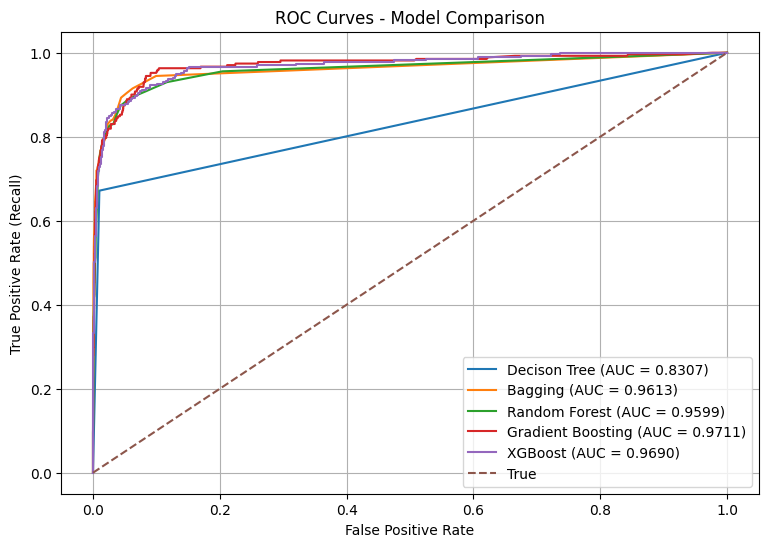

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for name, model in models.items():

    y_proba = cross_val_predict( # generate the predection for every sample but from model it didnt train sample
        model,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1]

    fpr, tpr, thresholds = roc_curve(y_train, y_proba)

    auc_score = roc_auc_score(y_train, y_proba)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.4f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--',)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves - Model Comparison')
plt.legend()
plt.grid()
plt.show()

we thrive for highest TPR as it represnts the benefit we take from the model .


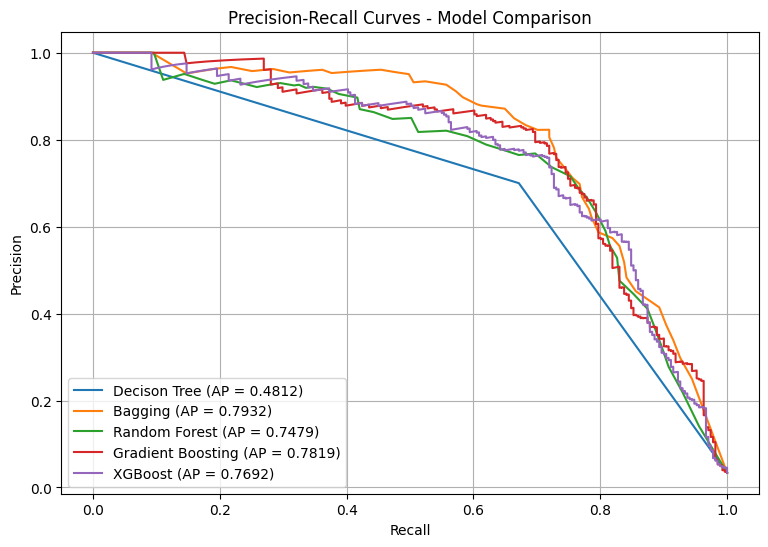

In [424]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(9, 6))

for name, model in models.items():

    y_proba = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_train, y_proba
    )

    ap_score = average_precision_score(y_train, y_proba)

    plt.plot(
        recall,
        precision,
        label=f'{name} (AP = {ap_score:.4f})'
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves - Model Comparison')
plt.legend()
plt.grid()
plt.show()

we want to get down to top right region , where both precision and recall are maximum ..so that we correctly detect failure and dont dont predict falsly even if failure occour. 